# Setting up and testing error signals for Virgo

This notebook walks through the chain of actions to bring the Virgo model to the point where the length sensing error signals can be set up and tested. It follows `examples/virgo/virgotools_base.ipynb`, with focus on the sensing plots drawn with the `plot_sensing_matrix` function from ifotools.

In [1]:
import finesse
from finesse.analysis.actions import OptimiseRFReadoutPhaseDC, RunLocks, SensingMatrixDC, SetLockGains
from finesse.analysis.actions.optimisation import Maximize, Minimize
from finesse.analysis.actions.random import Change
from finesse.analysis.actions.series import Series
from finesse.analysis.actions.temporary import TemporaryParameters

from ifotools.finesse import model_info, plotting
from ifotools.virgo import model_info as model_info_virgo
from ifotools.virgo import pretuning as pretuning_virgo

finesse.init_plotting()

## 1. Load the base model

The model comes from the common Virgo file plus the additional katscript with the readouts used by the length sensing and control system.

In [2]:
base = finesse.Model()
base.parse_file("../virgokatfiles/00_virgo_common_file.kat")
base.parse_file("../virgokatfiles/01_additional_katscript.kat")

important_dofs = ["DARM", "CARM", "MICH", "PRCL", "SRCL"]

## 2. Adjust recycling cavity lengths

The PRC and SRC lengths are set to match the RF modulation frequencies.

In [3]:
base2 = base.deepcopy()
pretuning_virgo.adjust_prc_length(base2, verbose=False)
pretuning_virgo.adjust_src_length(base2, verbose=False)

## 3. Pretuning with the carrier

The carrier power is used to set the resonance conditions: arms on resonance, dark fringe at the output, PRC and SRC on resonance, then the SRC offset by 90 degrees for resonant sideband extraction.

In [4]:
base3 = base2.deepcopy()
# fmt: off
base3.run(
    TemporaryParameters(
        Series(
            Change({"eom6.midx": 0, "eom8.midx": 0, "eom56.midx": 0,
                    "SR.misaligned": True, "PR.misaligned": True,
                    "SRAR.misaligned": True, "PRAR.misaligned": True}),
            # Maximise arm power
            Maximize("B7_DC", "NE_z.DC", bounds=[-180, 180], tol=1e-14),
            Maximize("B8_DC", "WE_z.DC", bounds=[-180, 180], tol=1e-14),
            # Minimise dark fringe power
            Minimize("B1_DC", "MICH.DC", bounds=[-180, 180], tol=1e-14),
            # Bring in PR
            Change({"PR.misaligned": False}),
            # Maximise PRC power
            Maximize("CAR_AMP_BS", "PRCL.DC", bounds=[-180, 180], tol=1e-14),
            # Bring in SR
            Change({"SR.misaligned": False}),
            # Maximise SRC power, then offset by 90 degrees
            Change({"SRCL.DC": 0}),
            Maximize("B1_DC", "SRCL.DC", bounds=[-180, 180], tol=1e-14),
            Change({"SRCL.DC": -90}, relative=True),
        ),
        exclude=("PR.phi", "NI.phi", "NE.phi", "WI.phi", "WE.phi", "SR.phi",
                 "NE_z.DC", "WE_z.DC", "MICH.DC", "PRCL.DC", "SRCL.DC"),
    )
)
# fmt: on
model_info_virgo.print_powers(base3)

┌─────────────┬─────────┬───────────────┬─────────────┐
│ Location    │ Node    │ Carrier power │ Total power │
╞═════════════╪═════════╪═══════════════╪═════════════╡
│ North arm   │ NE.p1.o │ 232.32 kW     │ 232.32 kW   │
│ West arm    │ WE.p1.o │ 230.63 kW     │ 230.63 kW   │
│ PRC         │ BS.p1.i │ 1.6392 kW     │ 1.7694 kW   │
│ Dark fringe │ B1.p1.i │ 3.2422 uW     │ 58.47 uW    │
└─────────────┴─────────┴───────────────┴─────────────┘



## 4. DARM offset

Testing setting the DARM DC offset so that 4 mW of carrier light leaks out at the dark port.

In [5]:
base4 = base3.deepcopy()
# fmt: off
base4.run(
    Series(
        TemporaryParameters(
            Series(
                Change({"eom6.midx": 0, "eom8.midx": 0, "eom56.midx": 0}),
                Minimize("B1_DC", "DARM.DC", tol=1e-10),
                Minimize("B1_DC", "DARM.DC", method=None, offset=4e-3, tol=1e-14,
                         bounds=[base4.DARM.DC - 90, base4.DARM.DC]),
            ),
            exclude=("NE_z.DC", "WE_z.DC", "DARM.DC"),
        )
    )
)
# fmt: on
model_info_virgo.print_powers(base4)

┌─────────────┬─────────┬───────────────┬─────────────┐
│ Location    │ Node    │ Carrier power │ Total power │
╞═════════════╪═════════╪═══════════════╪═════════════╡
│ North arm   │ NE.p1.o │ 232.3 kW      │ 232.3 kW    │
│ West arm    │ WE.p1.o │ 230.62 kW     │ 230.62 kW   │
│ PRC         │ BS.p1.i │ 1.6391 kW     │ 1.7693 kW   │
│ Dark fringe │ B1.p1.i │ 3.7411 mW     │ 3.7963 mW   │
└─────────────┴─────────┴───────────────┴─────────────┘



## 5. Add locks and readouts

One lock per degree of freedom, each using a readout output as error signal. For DARM two locks are defined: the RF lock on B1p_56, which is used first, and the DC lock on the B1 power with the 4 mW offset, which is still disabled and taken over at the end.

In [6]:
base5 = base4.deepcopy()
base5.parse(
    """
    lock CARM_lock B2_6.outputs.I CARM.DC 0 1e-11
    lock DARM_rf_lock B1p_56.outputs.I DARM.DC 0 1e-11
    lock DARM_dc_lock B1.outputs.DC DARM.DC 0 1e-11 offset=4m enabled=false
    lock MICH_lock B2_56.outputs.Q MICH.DC 0 1e-11
    lock PRCL_lock B2_8.outputs.I PRCL.DC 0 1e-11
    lock SRCL_lock B2_56.outputs.I SRCL.DC 0 1e-11
    """
)
readouts = ["B2_6", "B2_8", "B2_56", "B1p_56"]
model_info.print_lock_status(base5)

┌──────────────╥──────────┬─────────────┬──────────┬───────────┬──────┬────────┬─────────┐
│ Lock         ║ Readout  │ Phase [deg] │ Feedback │ Tolerance │ Gain │ Offset │ Enabled │
╞══════════════╬══════════╪═════════════╪══════════╪═══════════╪══════╪════════╪═════════╡
│ CARM_lock    ║ B2_6_I   │           0 │ CARM.DC  │     1e-11 │    0 │      0 │ True    │
│ DARM_rf_lock ║ B1p_56_I │           0 │ DARM.DC  │     1e-11 │    0 │      0 │ True    │
│ DARM_dc_lock ║ B1_DC    │             │ DARM.DC  │     1e-11 │    0 │  0.004 │ False   │
│ MICH_lock    ║ B2_56_Q  │           0 │ MICH.DC  │     1e-11 │    0 │      0 │ True    │
│ PRCL_lock    ║ B2_8_I   │           0 │ PRCL.DC  │     1e-11 │    0 │      0 │ True    │
│ SRCL_lock    ║ B2_56_I  │           0 │ SRCL.DC  │     1e-11 │    0 │      0 │ True    │
└──────────────╨──────────┴─────────────┴──────────┴───────────┴──────┴────────┴─────────┘



## 6. Sensing before demodulation phase optimisation

For reference, the DC sensing matrix from Finesse's own SensingMatrixDC action, printed and as radar plot. In the printed matrix the cell of each degree of freedom and error signal pair used by a lock is coloured.

┌──────╥──────────┬──────────┬─────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│      ║  B2_6_I  │  B2_6_Q  │ B2_8_I  │  B2_8_Q  │ B2_56_I  │ B2_56_Q  │ B1p_56_I │ B1p_56_Q │
╞══════╬══════════╪══════════╪═════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ DARM ║   -0.022 │   0.0038 │   0.016 │ -0.00098 │   -0.006 │    0.017 │  1.1E+02 │    1E+02 │
├──────╫──────────┼──────────┼─────────┼──────────┼──────────┼──────────┼──────────┼──────────┤
│ CARM ║      6.1 │       -1 │    -4.5 │     0.27 │      1.6 │     -4.7 │      0.3 │     0.27 │
├──────╫──────────┼──────────┼─────────┼──────────┼──────────┼──────────┼──────────┼──────────┤
│ MICH ║ -1.8E-05 │   -7E-05 │ 3.8E-05 │ -2.2E-06 │ -0.00044 │ -0.00023 │      0.4 │     0.36 │
├──────╫──────────┼──────────┼─────────┼──────────┼──────────┼──────────┼──────────┼──────────┤
│ PRCL ║  -0.0028 │  0.00053 │   0.016 │ -0.00095 │  0.00069 │   0.0039 │  0.00043 │ -0.00039 │
├──────╫──────────┼──────────┼─────────┼

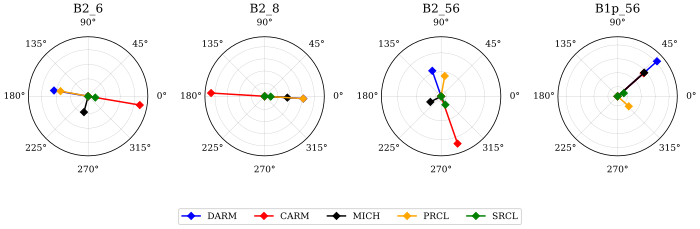

In [7]:
model_info.print_sensing_matrix(base5, important_dofs, readouts)
sensing_matrix = base5.run(SensingMatrixDC(important_dofs, readouts))
sm_fig, sm_axs = sensing_matrix.plot(1, 4, figsize=(10, 3.2))
sm_axs[-1].get_legend().remove()
sm_fig.legend(sm_axs[-1].lines, sensing_matrix.dofs, loc="lower center", ncols=len(sensing_matrix.dofs))
sm_fig.subplots_adjust(bottom=0.25);

The `plot_sensing_matrix` function from ifotools draws the sensing matrix at a signal frequency given in Hz. By default it draws one compass subplot per readout, with one arrow per degree of freedom, matching the arrangement of the SensingMatrixDC radar plot above. Since the model contains locks, the arrow of each readout and degree of freedom pair used by a lock is highlighted.

Note that the low-frequency response is not the same as the DC response when radiation pressure coupling is dominant. The DC sensing matrix holds the mirrors fixed, while the frequency response includes the motion of the suspended mirrors. Below the pendulum resonance (0.76 Hz in this model) the radiation pressure coupling dominates which can lead to a situation in which all degrees of freedom show similar readout pattern. Choosing a frequency slightly above the pendulum resonance frequency is recommended to get a more reasonable output. Here we use 20 Hz.

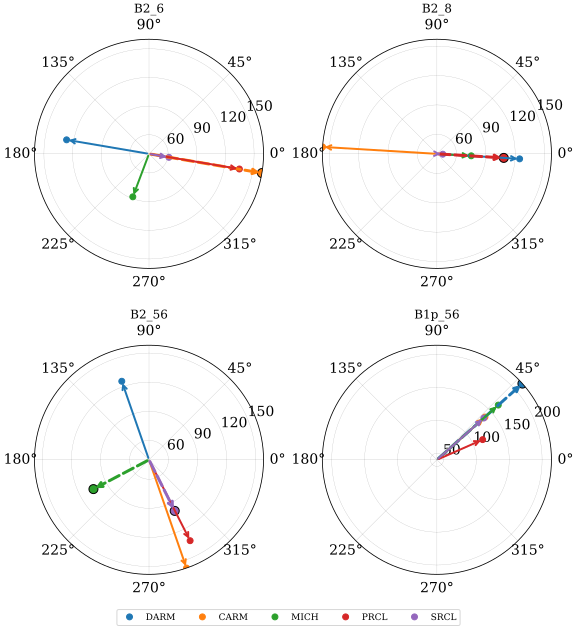

In [8]:
plotting.plot_sensing_matrix(base5, important_dofs, readouts, frequency=20, min_gain=40);

The same responses as numbers: given a frequency, `print_sensing_matrix` prints the responses at that frequency in the same form as the DC matrix, each reduced to a signed magnitude as in the compass plots, again with the lock cells coloured. The values are by default in watts per metre of drive, with an optional 'scale' factor for easier reading.

In [9]:
model_info.print_sensing_matrix(base5, important_dofs, readouts, frequency=20, scale=1e-6)

Response at 20 Hz, values scaled by 1e-06:
┌──────╥─────────┬─────────┬────────┬──────────┬─────────┬─────────┬──────────┬──────────┐
│      ║ B2_6_I  │ B2_6_Q  │ B2_8_I │  B2_8_Q  │ B2_56_I │ B2_56_Q │ B1p_56_I │ B1p_56_Q │
╞══════╬═════════╪═════════╪════════╪══════════╪═════════╪═════════╪══════════╪══════════╡
│ DARM ║    -2.3 │     0.4 │    1.7 │     -0.1 │   -0.63 │     1.8 │  3.8E+04 │  3.4E+04 │
├──────╫─────────┼─────────┼────────┼──────────┼─────────┼─────────┼──────────┼──────────┤
│ CARM ║      97 │     -17 │    -71 │      4.3 │      26 │     -76 │      5.8 │      5.2 │
├──────╫─────────┼─────────┼────────┼──────────┼─────────┼─────────┼──────────┼──────────┤
│ MICH ║ -0.0089 │  -0.024 │ 0.0057 │ -0.00033 │   -0.15 │  -0.081 │  1.3E+02 │  1.2E+02 │
├──────╫─────────┼─────────┼────────┼──────────┼─────────┼─────────┼──────────┼──────────┤
│ PRCL ║     6.2 │      -1 │   0.26 │   -0.016 │     2.2 │    -4.2 │     0.58 │     0.26 │
├──────╫─────────┼─────────┼────────┼──────────

## 7. Error signal scans before optimisation

The degree of freedom and error signal pairs are extracted from the locks.

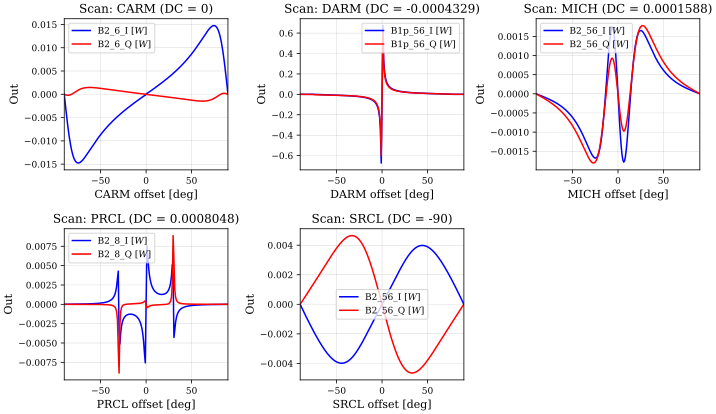

In [10]:
plotting.plot_error_signals(base5, plot_both_quadratures=True);

## 8. Optimise demodulation phases

Each error signal readout gets its demodulation phase set so that the signal of its degree of freedom appears in the I output.

In [11]:
base6 = base5.deepcopy()
sol = base6.run(OptimiseRFReadoutPhaseDC("DARM", "B1p_56_I", "CARM", "B2_6_I", "PRCL", "B2_8_I", "SRCL", "B2_56_I"))
sol.phases

{'B1p_56': 41.70359066873042,
 'B2_6': -9.65290239233059,
 'B2_8': -3.466376908742526,
 'B2_56': -63.307216316525036}

## 9. Sensing and error signals after optimisation

The same plots again. In the compass plots the arrows should now lie along the 0 and 180 degree axis for the readouts whose phase was optimised.

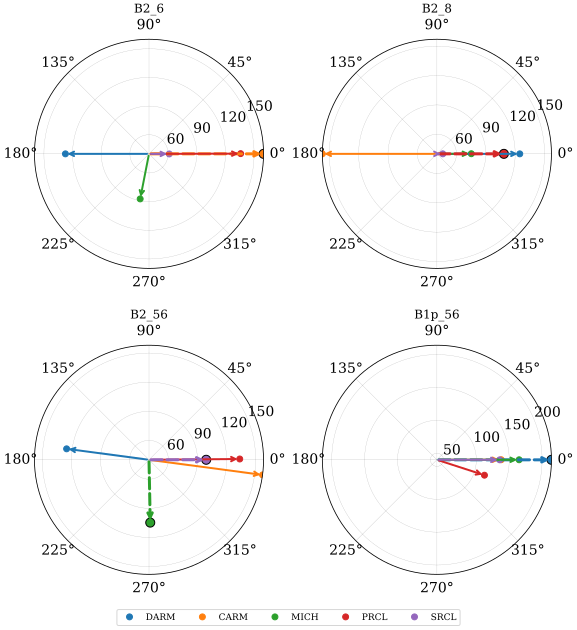

In [12]:
plotting.plot_sensing_matrix(base6, important_dofs, readouts, frequency=20, min_gain=40);

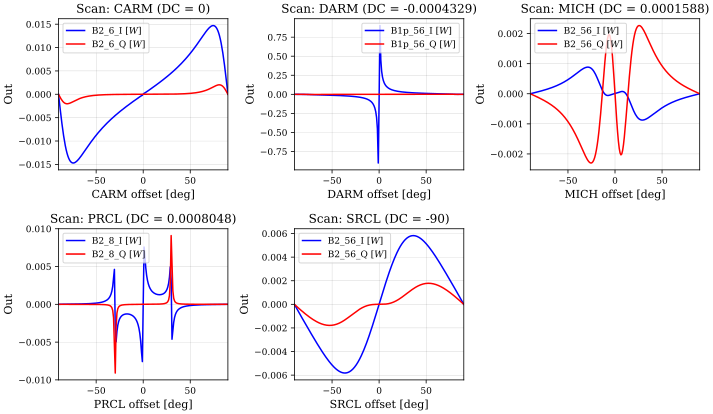

In [13]:
plotting.plot_error_signals(base6, plot_both_quadratures=True);

## 10. Run the locks

First a proper gain is computed for each lock from the sensing matrix with SetLockGains. Then the locks are run iteratively with these gains until all error signals are below their threshold values.

The RF lock for DARM has its zero crossing at the exact dark fringe, so running the locks removes the DC offset set in the pretuning. The offset is restored in the transition to the DC lock below.

In [14]:
base7 = base6.deepcopy()
base7.run(SetLockGains(verbose=True));

CARM_lock: -0.16133919066966468
DARM_rf_lock: -0.006568613000829646
MICH_lock: 1993.0286141583063
PRCL_lock: -63.74458838322132
SRCL_lock: -3814.0390479392227


In [15]:
result = base7.run(RunLocks(display_progress=False, show_progress_bar=False))
model_info.print_dofs(base7, dofs=important_dofs)
model_info.print_lock_status(base7)

┌──────╥────────────┬────────────────────────────────────────────────────────┐
│ DOF  ║     dof.DC │ node-amplitude pairs                                   │
╞══════╬════════════╪════════════════════════════════════════════════════════╡
│ DARM ║ -1.112e-07 │ NE.dofs.z -1, WE.dofs.z +1                             │
│ CARM ║ -9.736e-09 │ NE.dofs.z +1, WE.dofs.z +1                             │
│ MICH ║  0.0001905 │ NI.dofs.z -1, NE.dofs.z -1, WI.dofs.z +1, WE.dofs.z +1 │
│ PRCL ║   0.000802 │ PR.dofs.z +1                                           │
│ SRCL ║     -90.01 │ SR.dofs.z -1                                           │
└──────╨────────────┴────────────────────────────────────────────────────────┘

┌──────────────╥──────────┬─────────────┬──────────┬───────────┬───────────┬────────┬─────────┐
│ Lock         ║ Readout  │ Phase [deg] │ Feedback │ Tolerance │      Gain │ Offset │ Enabled │
╞══════════════╬══════════╪═════════════╪══════════╪═══════════╪═══════════╪════════╪═════════╡


In [16]:
model_info_virgo.print_powers(base7)

┌─────────────┬─────────┬───────────────┬─────────────┐
│ Location    │ Node    │ Carrier power │ Total power │
╞═════════════╪═════════╪═══════════════╪═════════════╡
│ North arm   │ NE.p1.o │ 232.32 kW     │ 232.32 kW   │
│ West arm    │ WE.p1.o │ 230.63 kW     │ 230.63 kW   │
│ PRC         │ BS.p1.i │ 1.6392 kW     │ 1.7694 kW   │
│ Dark fringe │ B1.p1.i │ 3.2422 uW     │ 58.47 uW    │
└─────────────┴─────────┴───────────────┴─────────────┘



## 11. Transition DARM to the DC lock

So far DARM is held by the RF lock on B1p_56, which can be easier to acquire and more robust but is worse for low-noise performance. The science mode operating condition uses the DC lock for DARM on the B1 power, with the 4 mW offset we tested also in the pretuning. For the transition the RF lock is disabled, DARM is kicked away from the dark fringe so that the DC lock sees an error signal on the correct side, the gain of the DC lock is computed from the sensing matrix, and the locks are run again.

Note that SetLockGains computes the ideal gain for each loop on its own. In a system of several coupled loops these gains can be too high and some loops start to fail. In practice the gains are then lowered manually, often by a factor of 2 or even 10 (see the gain_scale argument of SetLockGains). The computed gains are a good initial guess, not exact gains for a coupled system. In this example without defects they work as they are.

In [17]:
base8 = base7.deepcopy()
base8.DARM_rf_lock.enabled = False
# Move DARM away from the dark fringe so that the DC lock sees an error
# signal on the correct side
base8.DARM.DC += 0.5e-3
base8.DARM_dc_lock.enabled = True
base8.run(SetLockGains("DARM_dc_lock", verbose=True));
result = base8.run(RunLocks(display_progress=False, show_progress_bar=False))
model_info.print_dofs(base8, dofs=important_dofs)
model_info.print_lock_status(base8)

DARM_dc_lock: -0.05014335525444318
┌──────╥───────────┬────────────────────────────────────────────────────────┐
│ DOF  ║    dof.DC │ node-amplitude pairs                                   │
╞══════╬═══════════╪════════════════════════════════════════════════════════╡
│ DARM ║ 0.0004444 │ NE.dofs.z -1, WE.dofs.z +1                             │
│ CARM ║ 1.609e-06 │ NE.dofs.z +1, WE.dofs.z +1                             │
│ MICH ║ 0.0001889 │ NI.dofs.z -1, NE.dofs.z -1, WI.dofs.z +1, WE.dofs.z +1 │
│ PRCL ║  0.000802 │ PR.dofs.z +1                                           │
│ SRCL ║    -90.01 │ SR.dofs.z -1                                           │
└──────╨───────────┴────────────────────────────────────────────────────────┘

┌──────────────╥──────────┬─────────────┬──────────┬───────────┬───────────┬────────┬─────────┐
│ Lock         ║ Readout  │ Phase [deg] │ Feedback │ Tolerance │      Gain │ Offset │ Enabled │
╞══════════════╬══════════╪═════════════╪══════════╪═══════════╪══════

In [18]:
model_info_virgo.print_powers(base8)

┌─────────────┬─────────┬───────────────┬─────────────┐
│ Location    │ Node    │ Carrier power │ Total power │
╞═════════════╪═════════╪═══════════════╪═════════════╡
│ North arm   │ NE.p1.o │ 232.3 kW      │ 232.3 kW    │
│ West arm    │ WE.p1.o │ 230.62 kW     │ 230.62 kW   │
│ PRC         │ BS.p1.i │ 1.6391 kW     │ 1.7693 kW   │
│ Dark fringe │ B1.p1.i │ 3.9448 mW     │ 4 mW        │
└─────────────┴─────────┴───────────────┴─────────────┘

